# 070 CASE 110 — Weather-based image selection

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with the
> [metafilter](https://github.com/DigitalEarthSwedenExperimentalLab/space-datalab-metafilter) library. Not a validated product or service, and without support.

**Question:** Can weather data tell us in advance which Sentinel-2 overpasses are worth downloading?

**Area:** Farmland east of Lund (Skåne), May to August 2024.

**Partners:** Co-developed with partners in SDL 3.0's meteorological-metadata pilot.

**Data:** ERA5 and ERA5-Land reanalysis through the [Open-Meteo](https://open-meteo.com) archive
(no account needed); Copernicus Sentinel-2 L2A scene classification from
[Digital Earth Sweden](https://digitalearth.se) through openEO.

**Licence:** Apache-2.0, like the rest of the repository. ERA5 contains modified Copernicus Climate
Change Service information; Open-Meteo data are CC BY 4.0.

## Before you run

Run the notebook from a checkout of the repository (it reads the profiles in `filters/`), with the
library installed at the commit these results were produced with:

```bash
git clone https://github.com/DigitalEarthSwedenExperimentalLab/space-datalab-metafilter.git && cd space-datalab-metafilter && git checkout 9b79f60
pip install -e . openeo matplotlib
```

The weather part needs no account. The check against real scenes reads Sentinel-2 from Digital Earth
Sweden, so each user logs in with their own DES account in the *Log in* cell before section 4, either
with EGI in the browser or with a DES username and password. The login is yours: no credentials are
shared or saved in the notebook. A run takes a few minutes.

## 1. Method

```
Open-Meteo ERA5 (hourly) → daily metrics (temperature, rain, radiation, cloud at 10:30 UTC, soil moisture …)
                         → filter profile (rules) → days worth looking at
DES Sentinel-2 SCL       → actual cloud fraction over the area on every overpass  → how good was the filter?
```

A filter profile is a set of rules on daily weather metrics. We compare two shipped profiles: the
original two-rule filter (warm and dry) and the extended Open-Meteo profile with ten rules, including
cloud cover at the satellite's overpass time. The test is simple: on the days the filter keeps, is
the area actually clear in the Sentinel-2 scene classification?

## 2. Daily weather metrics

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from metafilter import fetch_daily_meteorology
from metafilter.core import apply_metafilter

AOI = {"west": 13.25, "south": 55.70, "east": 13.30, "north": 55.73}  # farmland east of Lund
SEASON = ("2024-05-01", "2024-08-31")
LOOKBACK_START = "2024-04-01"  # 30-day rules need a month of history

met = fetch_daily_meteorology(bbox_wgs84=AOI, date_start=LOOKBACK_START, date_end=SEASON[1],
                              cache_dir=".cache/metafilter")
daily = met.frame[pd.to_datetime(met.frame["date"]) >= SEASON[0]].reset_index(drop=True)
print(f"{len(daily)} days from {met.source}, {daily['date'].iloc[0]} to {daily['date'].iloc[-1]}")
daily[["date", "mean_temp_c", "total_precip_mm", "ssrd_mj_m2", "tcc_mean_overpass", "lcc_mean_overpass"]].head()

123 days from open-meteo, 2024-05-01 to 2024-08-31


,date,mean_temp_c,total_precip_mm,ssrd_mj_m2,tcc_mean_overpass,lcc_mean_overpass
0,2024-05-01,13.770841,0.0,22.845600,0.09,0.00
1,2024-05-02,13.683339,0.0,23.705999,0.31,0.00
2,2024-05-03,13.262508,0.1,23.306400,0.23,0.00
3,2024-05-04,13.395843,0.0,17.215200,0.98,0.79
4,2024-05-05,12.470840,5.6,11.012400,0.97,0.28


## 3. Apply the two filter profiles

In [2]:
profiles = {
    "baseline (2 rules)": json.loads(Path("../filters/metafilter.json").read_text()),
    "Open-Meteo extended (10 rules)": json.loads(Path("../filters/sentinel2_openmeteo.json").read_text()),
}
selections = {}
for name, profile in profiles.items():
    selected, rules = apply_metafilter(daily, profile)
    selections[name] = set(selected.loc[selected["selected"], "date"].astype(str))
    print(f"\n{name}: {len(selections[name])} of {len(daily)} days kept")
    for r in rules:
        print(f"  {r['name']:45s} passes {r['passed_days']:3d} of {r['valid_days']} days")


baseline (2 rules): 50 of 123 days kept
  Daily mean temperature                        passes  89 of 123 days
  Daily total precipitation                     passes  72 of 123 days

Open-Meteo extended (10 rules): 5 of 123 days kept
  Daily mean temperature                        passes 122 of 123 days
  Today's precipitation                         passes  67 of 123 days
  Precipitation, previous 48 hours              passes  60 of 123 days
  Precipitation, previous 7 days                passes 104 of 123 days
  Total cloud cover at overpass                 passes  24 of 123 days
  Low cloud cover at overpass                   passes  62 of 123 days
  Daily solar radiation                         passes 107 of 123 days
  Cumulative precipitation, previous 30 days    passes 117 of 123 days
  Growing degree days, previous 30 days (base 5 C) passes 101 of 123 days
  Rootzone moisture, previous 30 days           passes 123 of 123 days


## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    des.authenticate_basic(input("DES username: "), getpass("DES password: "))
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires

## 4. Actual cloud cover on every Sentinel-2 overpass

In [4]:
import xarray as xr

# DES answers at most 20 time steps per request, so fetch the season month by month
months = pd.date_range(SEASON[0], "2024-09-01", freq="MS").strftime("%Y-%m-%d")
parts = []
for start, end in zip(months[:-1], months[1:]):
    cube = des.load_collection("s2_msi_l2a", spatial_extent=AOI, temporal_extent=[start, end], bands=["scl"])
    cube.download(f"scl_{start}.nc", format="netCDF")
    parts.append(xr.open_dataset(f"scl_{start}.nc")["scl"])
time_dim = next(d for d in parts[0].dims if d in ("t", "time"))
scl = xr.concat(parts, dim=time_dim)
rows = []
for t in scl[time_dim].values:
    a = scl.sel({time_dim: t}).values
    valid = (a > 0) & (a != 255)  # 0 = no data
    if valid.mean() < 0.9:
        continue  # area at the swath edge
    cloud = np.isin(a[valid], [3, 8, 9, 10]).mean()  # cloud shadow, cloud medium/high, cirrus
    rows.append({"date": str(pd.Timestamp(t).date()), "cloud_fraction": float(cloud)})
overpasses = pd.DataFrame(rows).groupby("date", as_index=False)["cloud_fraction"].min()
clear = overpasses["cloud_fraction"] < 0.10
print(f"{len(overpasses)} overpasses with full coverage; {clear.sum()} clear (< 10 % cloud)")

49 overpasses with full coverage; 12 clear (< 10 % cloud)


## 5. How good was each filter?

In [5]:
summary = []
for name, days in selections.items():
    kept = overpasses["date"].isin(days)
    summary.append({
        "profile": name,
        "overpasses kept": int(kept.sum()),
        "clear among kept": int((kept & clear).sum()),
        "share of kept that is clear": (kept & clear).sum() / kept.sum() if kept.any() else np.nan,
        "clear overpasses found": f"{int((kept & clear).sum())} of {int(clear.sum())}",
        "median cloud, kept": overpasses.loc[kept, "cloud_fraction"].median(),
        "median cloud, rejected": overpasses.loc[~kept, "cloud_fraction"].median(),
    })
print(f"no filter: {clear.sum()} of {len(overpasses)} overpasses clear ({clear.mean():.0%})")
pd.DataFrame(summary).round(2)

no filter: 12 of 49 overpasses clear (24%)


,profile,overpasses kept,clear among kept,share of kept that is clear,clear overpasses found,"median cloud, kept","median cloud, rejected"
0,baseline (2 rules),20,8,0.40,8 of 12,0.38,0.99
1,Open-Meteo extended (10 rules),4,3,0.75,3 of 12,0.00,0.88


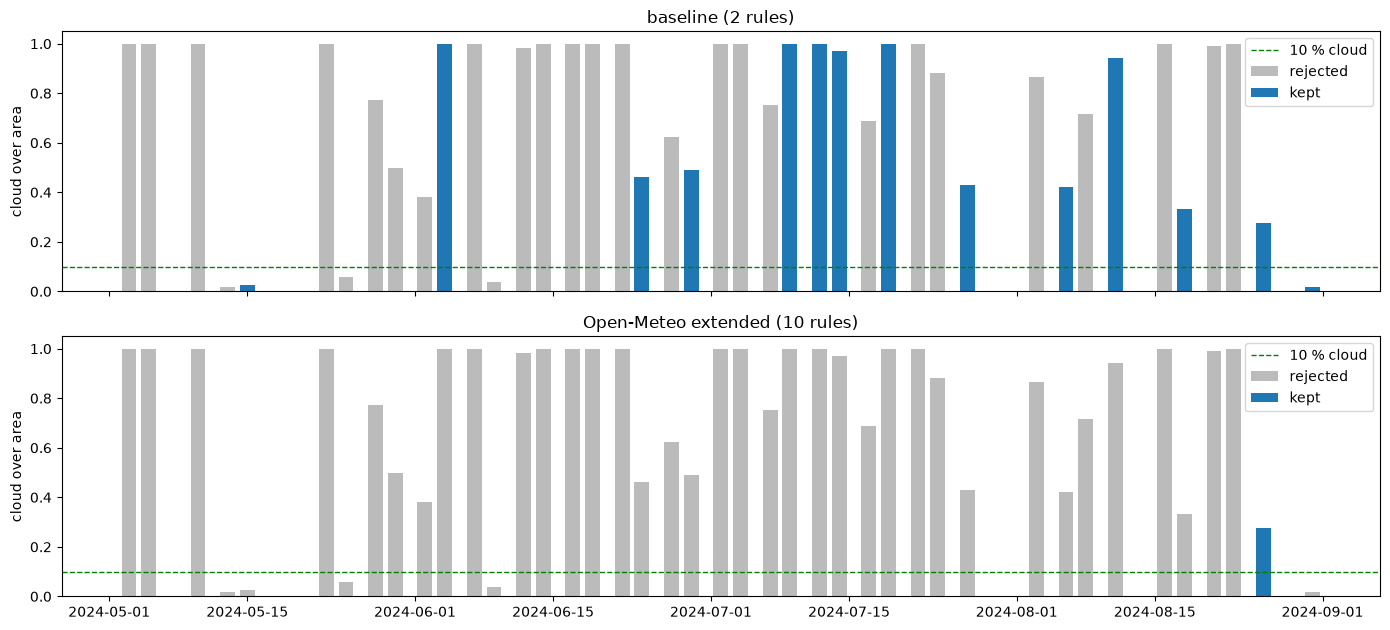

In [6]:
fig, axes = plt.subplots(len(selections), 1, figsize=(14, 3.2 * len(selections)), sharex=True)
dates = pd.to_datetime(overpasses["date"])
for ax, (name, days) in zip(np.atleast_1d(axes), selections.items()):
    kept = overpasses["date"].isin(days)
    ax.bar(dates[~kept], overpasses.loc[~kept, "cloud_fraction"], width=1.5, color="#bbbbbb", label="rejected")
    ax.bar(dates[kept], overpasses.loc[kept, "cloud_fraction"], width=1.5, color="#1f77b4", label="kept")
    ax.axhline(0.10, color="green", linestyle="--", linewidth=1, label="10 % cloud")
    ax.set_ylabel("cloud over area")
    ax.set_title(name)
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6. Interpretation

The filter is useful if the overpasses it keeps are clearer than those it rejects, without losing
too many of the clear ones. The table above gives both numbers for one field and one summer, so
it shows how to evaluate a profile, not how well the method works in general. ERA5 is a reanalysis
at about 31 km (radiation, rain, cloud) and 9 km (land variables): a local shower or a single cloud
over the field can differ from the grid cell.

**Next steps:** run several areas and years, tune thresholds on one year and test them on another,
and use the result to limit which scenes a pipeline downloads.

## Provenance

The saved outputs were produced by running this notebook top to bottom at metafilter commit
`9b79f60`, with weather from the Open-Meteo archive and scene classification from Digital Earth
Sweden.